# Notebook 4: Programming a leak valve through its RS232 port

*Python for Instrumentation and Laboratory Experiments, Pr. T. Angot*

Control the VAT Series 590 leak valve through RS232: test the device status, check the valve position, set a chosen position, hold it for a certain time, and close it.

## Functioning of the valve

- A valve plate, moved by a stepper motor, changes the conductance of the opening and so the gas flow into the vacuum chamber. Full stroke = 100 000 steps (0 = closed, 100 000 = open), about 3.5 s from closed to open.
- Two modes: **position control** (we give a position) and **pressure control** (the controller reads a gauge on its SENSOR input and moves the plate to reach a pressure setpoint).
- RS232 commands are only accepted in **remote** operation. The interlock inputs OPEN / CLOSE have priority over RS232.
- At power up the valve synchronizes (position unknown, `A:` returns 999999), then closes. On power failure it stays where it is.

## Communication

9600 baud, **7 data bits, even parity**, 1 stop bit. Commands are case sensitive and end with `\r\n`. The valve acknowledges each command within 10 ms (wait for it before the next one) or answers an error `E:xxxxxx`.

| Command | Function | Answer |
|---|---|---|
| `i:30` | status | `i:30abcdefgh`, a = access (0 local, 1 remote), b = mode (2 position control, 3 closed, 4 open, 6 hold, 8/9 interlock, D safety, E fatal error), d = warning |
| `A:` | position | `A:aaaaaa` |
| `R:aaaaaa` | go to position aaaaaa | `R:` |
| `H:` | hold the current position | `H:` |
| `C:` | close | `C:` |

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import serial
import serial.tools.list_ports as port_list

## Program

In [2]:
VALVE_SETTINGS = dict(baudrate=9600, bytesize=serial.SEVENBITS, parity=serial.PARITY_EVEN,
                      stopbits=serial.STOPBITS_ONE, timeout=1)

ACCESS_MODES = {'0': 'local', '1': 'remote', '2': 'locked remote'}
CONTROL_MODES = {'0': 'initialization', '1': 'synchronization', '2': 'position control', '3': 'closed',
                 '4': 'open', '5': 'pressure control', '6': 'hold', '8': 'interlock open',
                 '9': 'interlock closed', 'C': 'power failure', 'D': 'safety mode', 'E': 'fatal error'}
ERRORS = {'E:000001': 'parity error', 'E:000002': 'input buffer overflow', 'E:000003': 'framing error',
          'E:000004': 'overrun', 'E:000010': 'CR or LF missing', 'E:000011': ': missing',
          'E:000012': 'invalid number of characters', 'E:000023': 'invalid value',
          'E:000030': 'value out of range', 'E:000041': 'command not applicable for this hardware',
          'E:000060': 'ZERO disabled', 'E:000080': 'command not accepted: valve in local operation',
          'E:000081': 'command not accepted: service interface locked',
          'E:000082': 'command not accepted: synchronization, interlock, safety mode or fatal error',
          'E:000089': 'not accepted in calibration and test mode'}

POSITION_MAX = 100000
UNKNOWN_POSITION = 999999

class ValveError(Exception):
    pass

def send(ser, cmd):
    # send one command, wait for the acknowledgement and check it
    ser.reset_input_buffer()
    ser.write((cmd + "\r\n").encode("ascii"))
    reply = ser.readline().decode("ascii", errors="replace").strip()
    if reply == "":
        raise ValveError(f"no answer to {cmd!r}")
    if reply.startswith("E:"):
        raise ValveError(f"{cmd!r} refused: {reply}, {ERRORS.get(reply, 'unknown error')}")
    expected = cmd if cmd.startswith("i:") or cmd == "A:" else cmd[:2]
    if not reply.startswith(expected):
        raise ValveError(f"unexpected answer {reply!r} to {cmd!r}")
    return reply

def get_status(ser):
    s = send(ser, "i:30")[4:]
    return {'access': ACCESS_MODES.get(s[0], s[0]),
            'mode': CONTROL_MODES.get(s[1], s[1]),
            'warning': s[3] == '1'}

def get_position(ser):
    p = int(send(ser, "A:")[2:])
    return None if p == UNKNOWN_POSITION else p

def set_position(ser, position):
    if not 0 <= position <= POSITION_MAX:
        raise ValueError(f"position must be between 0 and {POSITION_MAX}, not {position}")
    send(ser, f"R:{int(position):06d}")

In [3]:
def wait_for_position(ser, target, log, tolerance=100, timeout=30, poll=0.5, t0=0.0,
                      clock=time.time, wait=time.sleep):
    start = clock()
    while True:
        p = get_position(ser)
        log.append((clock() - t0, p, get_status(ser)['mode']))
        if p is not None and abs(p - target) <= tolerance:
            return p
        if clock() - start > timeout:
            raise ValveError(f"position {target} not reached after {timeout} s (last position: {p})")
        wait(poll)

def run_sequence(ser, position, hold_time, tolerance=100, poll=0.5, clock=time.time, wait=time.sleep):
    log = []
    t0 = clock()

    # 1. status
    status = get_status(ser)
    print("status:", status)
    if status['access'] == 'local':
        raise ValveError("valve in local operation, RS232 commands would be refused")
    if status['mode'] in ('interlock open', 'interlock closed', 'power failure', 'safety mode', 'fatal error'):
        raise ValveError(f"valve not ready: {status['mode']}")
    if status['warning']:
        print("warning:", send(ser, "i:51"))

    # 2. current position (unknown during synchronization)
    p = get_position(ser)
    while p is None:
        if clock() - t0 > 30:
            raise ValveError("position still unknown after 30 s")
        wait(1)
        p = get_position(ser)
    print(f"initial position: {p}")

    try:
        # 3. set the position
        set_position(ser, position)
        p = wait_for_position(ser, position, log, tolerance, poll=poll, t0=t0, clock=clock, wait=wait)
        print(f"t = {clock()-t0:5.1f} s: position {p} reached")

        # 4. hold it
        send(ser, "H:")
        print(f"t = {clock()-t0:5.1f} s: hold for {hold_time} s, mode = {get_status(ser)['mode']}")
        t_end = clock() + hold_time
        while clock() < t_end:
            wait(min(poll, t_end - clock()))
            log.append((clock() - t0, get_position(ser), get_status(ser)['mode']))
    finally:
        # 5. close, even after an error
        send(ser, "C:")
        wait_for_position(ser, 0, log, tolerance=0, poll=poll, t0=t0, clock=clock, wait=wait)
        print(f"t = {clock()-t0:5.1f} s: valve closed, mode = {get_status(ser)['mode']}")
    return log

Use with the real valve (30 % open for 60 s):

In [ ]:
for p in port_list.comports():
    print(p)

serial_address = "COM4"   # from the list above

with serial.Serial(serial_address, **VALVE_SETTINGS) as ser:
    log = run_sequence(ser, position=30000, hold_time=60)

## Test with a simulated valve

The valve was not available. The class below answers like the valve described in the manual (same commands, acknowledgements and error codes, plate moving at 100 000 steps per 3.5 s), with a virtual clock. **Simulated, not the real valve.**

In [4]:
class VirtualClock:
    def __init__(self):
        self.now = 0.0
    def time(self):
        return self.now
    def sleep(self, s):
        self.now += s

class FakeVAT590:
    speed = POSITION_MAX/3.5

    def __init__(self, clock, access='1'):
        self.clock = clock
        self.access = access
        self.mode = '3'
        self.position = 0.0
        self.target = 0.0
        self.last = clock.time()
        self.reply = b""

    def _move(self):
        now = self.clock.time()
        step = self.speed*(now - self.last)
        self.last = now
        if abs(self.target - self.position) <= step:
            self.position = self.target
        else:
            self.position += step*np.sign(self.target - self.position)

    def _answer(self, cmd):
        if cmd == "i:30":
            return f"i:30{self.access}{self.mode}000000"
        if cmd == "i:51":
            return "i:5100000000"
        if cmd == "A:":
            return f"A:{int(round(self.position)):06d}"
        if ":" not in cmd:
            return "E:000011"
        if self.access == '0':
            return "E:000080"
        if cmd == "C:":
            self.target, self.mode = 0, '3'
        elif cmd == "O:":
            self.target, self.mode = POSITION_MAX, '4'
        elif cmd == "H:":
            self.target, self.mode = self.position, '6'
        elif cmd.startswith("R:"):
            value = cmd[2:]
            if len(value) != 6 or not value.isdigit():
                return "E:000012"
            if int(value) > POSITION_MAX:
                return "E:000030"
            self.target, self.mode = int(value), '2'
        else:
            return "E:000023"
        return cmd[:2]

    def write(self, data):
        self.clock.sleep(0.01)
        self._move()
        text = data.decode("ascii")
        if not text.endswith("\r\n"):
            self.reply = b"E:000010\r\n"
        else:
            self.reply = (self._answer(text[:-2]) + "\r\n").encode("ascii")
        return len(data)

    def readline(self):
        r, self.reply = self.reply, b""
        return r

    def reset_input_buffer(self):
        self.reply = b""

status: {'access': 'remote', 'mode': 'closed', 'warning': False}
initial position: 0
t =   1.1 s: position 30000 reached
t =   1.1 s: hold for 60 s, mode = hold
t =  62.2 s: valve closed, mode = closed


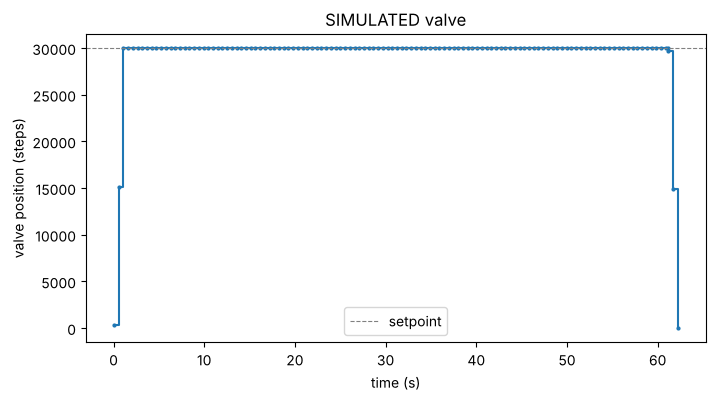

In [5]:
clock = VirtualClock()
log = run_sequence(FakeVAT590(clock), position=30000, hold_time=60, clock=clock.time, wait=clock.sleep)

t_log = np.array([row[0] for row in log])
p_log = np.array([row[1] for row in log])
plt.figure(figsize=(8, 4))
plt.step(t_log, p_log, where='post', marker='.', ms=4)
plt.axhline(30000, color='gray', ls='--', lw=0.8, label='setpoint')
plt.xlabel("time (s)")
plt.ylabel("valve position (steps)")
plt.title("SIMULATED valve")
plt.legend()
plt.show()

Error cases: position out of range, refused command, valve in local operation.

In [6]:
clock = VirtualClock()
for test in (lambda: set_position(FakeVAT590(clock), 150000),
             lambda: send(FakeVAT590(clock), "R:150000"),
             lambda: run_sequence(FakeVAT590(clock, access='0'), 30000, 60, clock=clock.time, wait=clock.sleep)):
    try:
        test()
    except (ValueError, ValveError) as e:
        print("->", e)

-> position must be between 0 and 100000, not 150000
-> 'R:150000' refused: E:000030, value out of range
status: {'access': 'local', 'mode': 'closed', 'warning': False}
-> valve in local operation, RS232 commands would be refused
